# 04 · Our model against EPSS (Q4)

**DSCI 510 project: Anticipating Attacks on Software Flaws**

This notebook answers the project's fourth question:

> **Q4.** How does our publication-day ranking compare with EPSS, the industry's public exploit
> prediction score, on the same CVEs? Where do they agree, where do they differ, and is either
> better at catching the CVEs that end up exploited?

**EPSS in one paragraph.** The Exploit Prediction Scoring System, run by FIRST, gives every published
CVE a score each day: its estimate of "the probability of exploitation activity being observed over
the next 30 days". Its training labels come from partners' sensors (intrusion detection, honeypots,
endpoint telemetry), not from KEV. Its inputs, in the version that scored all of 2024 (v2023.03.01),
include public exploit code (Exploit-DB, GitHub, Metasploit), mentions on lists such as **CISA's KEV
catalogue**, Google Project Zero and Zero Day Initiative, social-media chatter, scanners, the CVSS
vector, the CWE and the vendor. (Sources: first.org/epss/model and the EPSS v3 paper,
arXiv:2302.14172.)

**Why the comparison needs care.** The two rankings are not built for the same moment or the same
question:

| | Our final model | EPSS |
|:--|:--|:--|
| When it scores | on the day of publication | every day; here 1, 7 and 30 days after publication |
| What it predicts | listed in KEV within 365 days | exploitation activity seen by sensors in the next 30 days |
| Can it see a KEV listing? | no | yes: a KEV listing is one of its inputs |

So the notebook compares them in two ways: **as a team would meet them** (all 2024 CVEs), and
**on equal information** (leaving out, for each EPSS day, the exploited CVEs that KEV had already
listed by then, since EPSS could read that answer and our model could not).

| Stage | What happens |
|:--|:--|
| A · Setup | Settings, records, chart style, and the evaluation tools of `03_model.ipynb`, tested |
| B · Inputs | The 2024 scores of `03_model_test.ipynb`, the EPSS benchmark of `01_acquire_data.ipynb`, both checked |
| C · Head to head | Coverage of every ranking on all 2024 CVEs, paired differences, curves |
| D · Equal information | When exploited CVEs reach KEV; the comparison without already-listed CVEs; sensitivity checks |
| E · Disagreement | Which exploited CVEs each catches that the other misses, and from which publishers; a simple combination |
| F · Summary | Findings, checks and files |

**Inputs:** `data/processed/analysis_table.parquet`, `data/processed/epss_benchmark.parquet` (notebook 01),
and from `03_model_test.ipynb`: `data/processed/model_scores_test.parquet`, `results/q2_selection.json`,
`logs/model_log_test.json` and `logs/test_openings.json`. Run `03_model_test.ipynb` first.

**Outputs:** `results/q4_*.csv` and `results/q4_summary.json`, `figures/q4_*.png`,
`data/processed/q4_scores_test.parquet` (for the demo app) and the run log `logs/epss_log.json`.

**Runtime:** about a minute; nothing is downloaded and no model is fitted.

**The test year:** this notebook reads 2024 labels, but only to *measure*. No model, setting or
score from `03_model.ipynb` is changed, and every comparison below is fixed in Step 2 before any
result is computed. Nothing here re-opens the test year in the sense of `03_model_test.ipynb`: the
2024 scores were produced there, once.

---

## Stage A · Setup

### Step 1 · Libraries

**What we are doing:** importing the libraries and recording their versions.

In [1]:
import hashlib, json, re, sys
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import average_precision_score

VERSIONS = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(" | ".join(f"{name} {version}" for name, version in VERSIONS.items()))

python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | scipy 1.18.0 | scikit-learn 1.9.0 | matplotlib 3.11.0


**Reading the result:** one line of versions. No model is fitted here, so the versions only matter
for reproducing the tables exactly.

### Step 2 · Settings, fixed before any result

**What we are doing:** the folders, the evaluation settings (the same as in `03_model.ipynb`), and
every comparison this notebook will make.

**Why:** the comparisons are written down here, before a single coverage is computed, so that none of
them can be chosen because it flatters one side.

- **EPSS days:** 1, 7 and 30 days after publication, as collected by notebook 01. Day 1 is the earliest
  fair comparison (EPSS publishes once a day); days 7 and 30 show what waiting buys.
- **Unscored CVEs:** a CVE that EPSS had not yet scored on that day is placed **after every scored CVE**
  (all such CVEs tied). That is what a team ranking by EPSS that day would see. Step 14 repeats the
  comparison on CVEs scored at all three days, so EPSS is not penalised for gaps alone.
- **Equal information (Stage D):** an exploited CVE whose KEV listing date is on or before the day an
  EPSS score describes is left out of that day's comparison, for both rankings.
- **The combination (Stage E):** the average of the final model's rank and EPSS day 1's rank, with equal
  weights. It has no setting to tune, so it can be measured on 2024 without choosing anything there.

In [2]:
# ---- Folders ----
PROCESSED, RAW = Path("data") / "processed", Path("data") / "raw"
RESULTS, FIGURES, LOGS = Path("results"), Path("figures"), Path("logs")
for folder in (RESULTS, FIGURES, LOGS):
    folder.mkdir(parents=True, exist_ok=True)

# ---- Evaluation: exactly as in 03_model.ipynb ----
LABEL = "label_365"                       # listed in KEV within 365 calendar days of publication
SEED, N_BOOT = 510, 1000                  # fixed seed: bootstrap intervals repeat exactly
EFFORTS = [0.05, 0.10, 0.26]              # shares of new CVEs handled; 0.26 = the 'score 7.0+' rule
PRIMARY_EFFORT = 0.10

# ---- The rankings compared (fixed before any result) ----
SELECTION_FILE = Path("results") / "q2_selection.json"
for needed in (SELECTION_FILE, PROCESSED / "model_scores_test.parquet", PROCESSED / "epss_benchmark.parquet"):
    if not needed.exists():
        raise FileNotFoundError(f"{needed} not found: run 01_acquire_data.ipynb and 03_model_test.ipynb first")
SELECTION = json.loads(SELECTION_FILE.read_text(encoding="utf-8"))
FINAL = SELECTION["final_model"]                       # the model 03 chose on 2023
MODEL = "final model"                                  # its name in this notebook's tables
CVSS, PUBLISHER = "CVSS score, unscored slotted in", "Publisher's past rate"
HORIZONS = [1, 7, 30]                                  # EPSS scores 1, 7 and 30 days after publication
EPSS = {h: f"EPSS, day {h}" for h in HORIZONS}
UNSCORED = -1.0                                        # below every EPSS score (they lie between 0 and 1)
COMBINED = "average rank: final model + EPSS day 1"
print(f"final model: {FINAL} {SELECTION['candidates'][FINAL]['params']} | EPSS days {HORIZONS} | "
      f"efforts {EFFORTS}")

final model: LR · structured + text {'C': 0.1} | EPSS days [1, 7, 30] | efforts [0.05, 0.1, 0.26]


**Reading the result:** the final model as `03_model.ipynb` froze it, the three EPSS days and the
three efforts. A `FileNotFoundError` names the notebook to run first.

### Step 3 · Recording checks and saving outputs

**What we are doing:** the record-keeping tools of `03_model.ipynb`, copied word for word, writing
this notebook's own run log, `logs/epss_log.json`.

In [3]:
def now_iso():
    "Current local time with its UTC offset."
    return dt.datetime.now().astimezone().isoformat(timespec="seconds")

def check(name, ok, **details):
    "Record one check and print its verdict. ok=True is PASS, False is FAIL, None is WARN."
    verdict = "WARN" if ok is None else ("PASS" if ok else "FAIL")
    RUN["checks"][name] = {"verdict": verdict, **details}
    print(f"{verdict}  {name}" + (f"  |  {details}" if details else ""))

def show_conditions(conditions):
    "Print a {description: passed} checklist; return the descriptions that failed."
    for description, passed in conditions.items():
        print(f"  {'ok ' if passed else 'NO '} {description}")
    return [description for description, passed in conditions.items() if not passed]

def save_table(df, name, index=True):
    "Save a result table as results/<name>.csv and remember it for the summary."
    path = RESULTS / f"{name}.csv"
    df.to_csv(path, index=index)
    RUN["files"].append(str(path))
    return path

def save_json(obj, path):
    "Write obj as indented JSON and remember the file."
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    RUN["files"].append(str(path))

def read_json(path):
    "A JSON file's content, or {} if it is missing or damaged."
    try:
        return json.loads(Path(path).read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

RUN = {"started": now_iso(), "checks": {}, "files": [], "versions": VERSIONS,
       "selection_sha256": SELECTION.get("sha256")}
LOG_FILE = LOGS / "epss_log.json"

**The chart style:** the same as in the other notebooks. Aqua is our final model; EPSS is shown in
three shades of violet (darker for later days); the baselines are grey.

In [4]:
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#898781"           # primary, secondary, muted text
SET_COLORS = {"structured": "#2a78d6", "text": "#eb6834", "structured + text": "#1baf7a"}
BASELINE_GREY = "#898781"

def pick_font(candidates=("Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans")):
    "The first installed font from the list (checked quietly, so matplotlib prints no warnings)."
    for name in candidates:
        try:
            font_manager.findfont(name, fallback_to_default=False)
            return name
        except ValueError:
            continue
    return "sans-serif"

plt.rcParams.update({
    "font.family": pick_font(), "font.size": 9.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_3, "ytick.color": INK_3, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "text.color": INK,
})

def save_figure(fig, name, note=None):
    "Add an optional note just below everything drawn, save figures/<name>.png, and show the figure."
    if note:
        fig.canvas.draw()                                         # lay out first, so the bounding box is final
        box = fig.get_tightbbox(fig.canvas.get_renderer())       # in inches
        fig.text(box.x0 / fig.get_figwidth(), (box.y0 - 0.08) / fig.get_figheight(), note,
                 ha="left", va="top", fontsize=8, color=INK_3)
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    RUN["files"].append(str(path))
    plt.show()
    plt.close(fig)

print("chart style ready | font:", pick_font())
EPSS_COLORS = {1: "#b9a8e8", 7: "#8e74d6", 30: "#5b43a8"}

chart style ready | font: Segoe UI


**Reading the result:** the font in use (Segoe UI on Windows; any fallback is fine).

### Step 4 · The evaluation tools

**What we are doing:** the measure of `03_model.ipynb`, copied word for word: the expected
**coverage** (share of exploited CVEs caught) when a team handles the top share of CVEs (the
**effort**), with tied scores split evenly, and the **paired bootstrap** that gives every ranking's
interval and every difference's interval from the same 1,000 resamples.

**Why ties matter even more here:** EPSS gives tens of thousands of new CVEs the very same low score
(Step 7 counts them). Without the even split, EPSS's coverage would depend on the order of the rows.

In [5]:
class Ranking:
    "CVEs sorted by score, highest first, with equal scores grouped. Computed once per model, reused."
    def __init__(self, score):
        score = np.asarray(score, dtype=float)
        if score.size == 0 or not np.isfinite(score).all():
            raise ValueError("scores must be finite and not empty")
        self.order = np.argsort(-score, kind="stable")
        ranked = score[self.order]
        self.group = np.cumsum(np.r_[True, ranked[1:] != ranked[:-1]]) - 1   # tie-group number, in rank order
        self.n_groups, self.n = int(self.group[-1]) + 1, score.size

def coverage(ranking, y, efforts, weights=None):
    "Expected (coverage, precision) when the top `effort` share is handled, ties split evenly."
    y = np.asarray(y, dtype=float)[ranking.order]
    w = np.ones(ranking.n) if weights is None else np.asarray(weights, dtype=float)[ranking.order]
    size = np.bincount(ranking.group, weights=w, minlength=ranking.n_groups)       # CVEs per tie group
    hits = np.bincount(ranking.group, weights=w * y, minlength=ranking.n_groups)   # exploited per group
    cum_size, cum_hits = np.cumsum(size), np.cumsum(hits)
    k = np.asarray(efforts, dtype=float) * cum_size[-1]                           # CVEs handled
    g = np.minimum(np.searchsorted(cum_size, k, side="left"), ranking.n_groups - 1)  # group holding the cut
    taken = np.divide(k - (cum_size[g] - size[g]), size[g], out=np.zeros_like(k), where=size[g] > 0)
    found = cum_hits[g] - hits[g] + hits[g] * np.clip(taken, 0, 1)
    total = cum_hits[-1]
    cov = found / total if total > 0 else np.full_like(k, np.nan)
    return cov, np.divide(found, k, out=np.full_like(k, np.nan), where=k > 0)

The cell above defines the measure. The next one adds its uncertainty, exactly as in `03_model.ipynb`.

In [6]:
def bootstrap_coverage(y, rankings, efforts, n_boot=N_BOOT, seed=SEED):
    "Coverage of every ranking on the same resamples of CVEs: an array (n_boot, rankings, efforts)."
    rng, n = np.random.default_rng(seed), len(y)
    out = np.empty((n_boot, len(rankings), len(efforts)))
    for b in range(n_boot):
        weights = np.bincount(rng.integers(0, n, n), minlength=n)    # how often each CVE was drawn
        for j, ranking in enumerate(rankings.values()):
            out[b, j] = coverage(ranking, y, efforts, weights)[0]
    return out

def tag(effort):
    "Column suffix for an effort: 0.10 -> '10'."
    return f"{round(effort * 100)}"

def evaluation_table(y, scores, efforts=EFFORTS, n_boot=N_BOOT):
    "Coverage (with 95% interval) and precision at each effort, and average precision, per model."
    rankings = {name: Ranking(s) for name, s in scores.items()}
    boot = bootstrap_coverage(y, rankings, efforts, n_boot)
    rows = []
    for j, (name, ranking) in enumerate(rankings.items()):
        cov, prec = coverage(ranking, y, efforts)
        row = {"model": name}
        for i, e in enumerate(efforts):
            low, high = np.percentile(boot[:, j, i], [2.5, 97.5])
            row.update({f"coverage_{tag(e)}": cov[i], f"coverage_{tag(e)}_low": low,
                        f"coverage_{tag(e)}_high": high, f"precision_{tag(e)}": prec[i]})
        row["average_precision"] = average_precision_score(y, scores[name])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), boot

def difference(table, boot, a, b, effort):
    "Coverage of model b minus model a at one effort, with its paired 95% interval."
    names, i = list(table.index), EFFORTS.index(effort)
    diffs = boot[:, names.index(b), i] - boot[:, names.index(a), i]
    estimate = table.loc[b, f"coverage_{tag(effort)}"] - table.loc[a, f"coverage_{tag(effort)}"]
    return (estimate, *np.percentile(diffs, [2.5, 97.5]))

**Testing the tools:** the six tests of `03_model.ipynb` on cases whose answers are known (a perfect
ranking; all scores tied; many ties against 3,000 random orders; weights against copies; identical
rankings; the same seed twice).

In [7]:
rng = np.random.default_rng(1)
y10 = np.array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0])
perfect = coverage(Ranking(np.arange(10, 0, -1)), y10, [0.2])
tied = coverage(Ranking(np.zeros(10)), y10, [0.3])

scores_t = np.round(rng.uniform(0, 1, 200), 1)              # 11 distinct values: many ties
y_t = (rng.random(200) < 0.2).astype(int)
formula = coverage(Ranking(scores_t), y_t, [0.2])[0][0]
brute = np.mean([y_t[np.lexsort((rng.random(200), -scores_t))][:40].sum() / y_t.sum() for _ in range(3000)])

doubled = coverage(Ranking(np.r_[scores_t, scores_t]), np.r_[y_t, y_t], EFFORTS)[0]
weighted = coverage(Ranking(scores_t), y_t, EFFORTS, weights=np.full(200, 2))[0]
same = bootstrap_coverage(y_t, {"a": Ranking(scores_t), "b": Ranking(scores_t)}, EFFORTS, n_boot=50)
again = bootstrap_coverage(y_t, {"a": Ranking(scores_t)}, EFFORTS, n_boot=50)

failed = show_conditions({
    "perfect ranking: 100% coverage and precision at 20% effort": np.allclose(perfect, [[1.0], [1.0]]),
    "all scores tied: coverage 30% at 30% effort": np.isclose(tied[0][0], 0.3),
    "ties: formula agrees with 3,000 random orders (within 0.01)": abs(formula - brute) < 0.01,
    "a weight of 2 equals listing every CVE twice": np.allclose(doubled, weighted),
    "identical rankings differ by exactly zero": np.array_equal(same[:, 0], same[:, 1]),
    "the same seed gives the same resamples": np.array_equal(same[:, 0], again[:, 0]),
})
print(f"tied example: formula {formula:.4f}, average of random orders {brute:.4f}")
check("A1-evaluation-selftest", not failed, tests=6, failed=failed)

  ok  perfect ranking: 100% coverage and precision at 20% effort
  ok  all scores tied: coverage 30% at 30% effort
  ok  ties: formula agrees with 3,000 random orders (within 0.01)
  ok  a weight of 2 equals listing every CVE twice
  ok  identical rankings differ by exactly zero
  ok  the same seed gives the same resamples
tied example: formula 0.2157, average of random orders 0.2156
PASS  A1-evaluation-selftest  |  {'tests': 6, 'failed': []}


**Reading the result:** six `ok` lines and `PASS`.

---

## Stage B · Inputs

### Step 5 · The 2024 scores of `03_model_test.ipynb`

**What we are doing:** loading the 2024 CVEs and the scores `03_model_test.ipynb` gave them, and
checking that those scores come from the single, logged opening of the test year with the frozen
choices.

**Why:** the comparison is only meaningful if "our model" is exactly the one chosen on 2023 and scored
once on 2024. The checks tie the scores to the test copy's run log and to the fingerprint of the
frozen choices.

In [8]:
table = pd.read_parquet(PROCESSED / "analysis_table.parquet")
test = table.loc[table["split"] == "test", ["cve_id", "published", "cna", LABEL, "kev_before_publication",
                                            "kev_date_added", "days_to_kev"]].reset_index(drop=True)
y = test[LABEL].to_numpy(int)
scores_03 = pd.read_parquet(PROCESSED / "model_scores_test.parquet")
log_03 = read_json(LOGS / "model_log_test.json").get("checks", {})
openings = read_json(LOGS / "test_openings.json") or []
acquisition = read_json(LOGS / "acquisition_log.json").get("checks", {})

content = {k: v for k, v in SELECTION.items() if k not in ("sha256", "frozen_at")}
failed = show_conditions({
    "the frozen choices match their fingerprint":
        hashlib.sha256(json.dumps(content, sort_keys=True, default=str).encode("utf-8")).hexdigest()
        == SELECTION.get("sha256"),
    "03_model_test.ipynb opened the test year with these choices (G1 fingerprint, G2 PASS)":
        log_03.get("G1-selection-frozen", {}).get("sha256") == SELECTION.get("sha256")
        and log_03.get("G2-test-evaluated", {}).get("verdict") == "PASS",
    "the 2024 scores are aligned with the 2024 CVEs": scores_03["cve_id"].equals(test["cve_id"]),
    "the rankings compared here have finite 2024 scores":
        all(c in scores_03 and np.isfinite(scores_03[c]).all() for c in (FINAL, CVSS, PUBLISHER)),
    "2024 exploited CVEs match the acquisition run":
        int(y.sum()) == acquisition.get("D2-analysis-table", {}).get("exploited", {}).get("test"),
})
print(f"2024: {len(test):,} CVEs, {int(y.sum())} exploited | test year opened {len(openings)} time(s)")
check("B1-inputs-from-03", False if failed else (True if len(openings) == 1 else None),
      openings=len(openings), failed=failed)

  ok  the frozen choices match their fingerprint
  ok  03_model_test.ipynb opened the test year with these choices (G1 fingerprint, G2 PASS)
  ok  the 2024 scores are aligned with the 2024 CVEs
  ok  the rankings compared here have finite 2024 scores
  ok  2024 exploited CVEs match the acquisition run
2024: 39,953 CVEs, 149 exploited | test year opened 1 time(s)
PASS  B1-inputs-from-03  |  {'openings': 1, 'failed': []}


**Reading the result:** five `ok` lines, the size of 2024, and `PASS` when the test year was opened
exactly once. `WARN` means it was opened more than once: the results still stand, but the report must
mention every opening. `FAIL` means the scores do not belong to the frozen model, and nothing below
should be used.

### Step 6 · The EPSS benchmark of `01_acquire_data.ipynb`

**What we are doing:** loading each 2024 CVE's EPSS score 1, 7 and 30 days after publication, and
checking the table: one row per CVE and day, scores between 0 and 1, one EPSS model version, and each
score taken from its target day or at most 2 days later (notebook 01's fallback when a day's file was
missing).

**Why:** EPSS scores change daily and its model is retrained from time to time. A benchmark mixing
model versions, or scores from much later days, would not be the EPSS a team saw at the time.

`epss_columns` reshapes the table to one row per CVE, in the same order as the scores of Step 5. For
each day it keeps the score and **the day it describes**: the day the score was taken from, or, for an
unscored CVE, the target day. Stage D compares that day with the KEV listing date.

In [9]:
def epss_columns(long, cve_ids):
    "One row per CVE (in the given order): EPSS at each horizon, and the day each score describes."
    out = pd.DataFrame({"cve_id": cve_ids})
    for h in HORIZONS:
        part = long.loc[long["horizon_days"] == h].set_index("cve_id").reindex(cve_ids)
        out[f"epss_{h}"] = part["epss"].to_numpy()
        out[f"day_{h}"] = part["score_day"].fillna(part["target_day"]).to_numpy()
    return out

epss_long = pd.read_parquet(PROCESSED / "epss_benchmark.parquet")
epss = epss_columns(epss_long, test["cve_id"])
scored = epss_long["epss"].notna()
versions = epss_long.loc[scored, "model_version"].value_counts().to_dict()
failed = show_conditions({
    "one row per 2024 CVE and EPSS day": len(epss_long) == len(test) * len(HORIZONS)
        and not epss_long.duplicated(["cve_id", "horizon_days"]).any()
        and set(epss_long["cve_id"]) == set(test["cve_id"]) and set(epss_long["horizon_days"]) == set(HORIZONS),
    "every score is between 0 and 1": bool(epss_long.loc[scored, "epss"].between(0, 1).all()),
    "every score is from its target day or at most 2 days later":
        bool(epss_long.loc[scored, "days_late"].between(0, 2).all()),
    "one EPSS model version for the whole year": len(versions) == 1,
    "the same table as the acquisition run": len(epss_long) == acquisition.get("E2-epss-benchmark", {}).get("rows"),
})
def late_share(h):
    "Share of day-h scores taken from a fallback day."
    return (epss_long.loc[(epss_long["horizon_days"] == h) & scored, "days_late"] > 0).mean()

summary = pd.DataFrame({h: {"scored": epss[f"epss_{h}"].notna().mean(),
                            "exploited scored": f"{int(epss.loc[y == 1, f'epss_{h}'].notna().sum())} of {int(y.sum())}",
                            "from a later day": late_share(h)} for h in HORIZONS}).T
print(summary.to_string(formatters={"scored": "{:.1%}".format, "from a later day": "{:.1%}".format}))
print(f"\nEPSS model version(s): {versions}")
check("B2-epss-benchmark", not failed, versions=versions,
      scored={h: round(float(epss[f"epss_{h}"].notna().mean()), 4) for h in HORIZONS}, failed=failed)

  ok  one row per 2024 CVE and EPSS day
  ok  every score is between 0 and 1
  ok  every score is from its target day or at most 2 days later
  ok  one EPSS model version for the whole year
  ok  the same table as the acquisition run
   scored exploited scored from a later day
1   92.0%       138 of 149             2.8%
7   98.3%       148 of 149             1.5%
30  98.7%       149 of 149             0.9%

EPSS model version(s): {'v2023.03.01': 115452}
PASS  B2-epss-benchmark  |  {'versions': {'v2023.03.01': 115452}, 'scored': {1: 0.9196, 7: 0.9834, 30: 0.9867}, 'failed': []}


**Reading the result:** five `ok` lines, then for each EPSS day the share of 2024 CVEs it had scored,
how many of the exploited ones, and the share taken from a fallback day; then the model version.
Notebook 01 already reported the gaps as `WARN` (E1, E2): they are part of the comparison, not an error.

*In the run of 15 Nov 2026:* EPSS had scored 92.0% of 2024 CVEs one day after publication (138 of the 149 exploited ones),
98.3% after 7 days (148) and 98.7% after 30 days (all 149); 0.9–2.8% of scores came from a fallback day.
One model, v2023.03.01, scored the whole year.

### Step 7 · What EPSS scores look like soon after publication

**What we are doing:** for each day, counting the distinct EPSS values, the most common value and the
share of scored CVEs that share it, and the median score of exploited and other CVEs.

**Why:** a ranking can only separate CVEs whose scores differ. If most new CVEs share one score, EPSS
cannot rank them against each other at all, and the tie rule of Step 4 decides its coverage there.

In [10]:
rows = {}
for h in HORIZONS:
    s = epss[f"epss_{h}"]
    counts = s.value_counts()
    rows[EPSS[h]] = {"distinct values": s.nunique(), "most common value": counts.index[0],
                     "share at that value": counts.iloc[0] / s.notna().sum(),
                     "median, exploited": s[y == 1].median(), "median, others": s[y == 0].median()}
q4_epss_shape = pd.DataFrame(rows).T
print(q4_epss_shape.to_string(formatters={"share at that value": "{:.1%}".format, "most common value": "{:.5f}".format,
                                          "median, exploited": "{:.5f}".format, "median, others": "{:.5f}".format}))
save_table(q4_epss_shape, "q4_epss_shape")

              distinct values most common value share at that value median, exploited median, others
EPSS, day 1             117.0           0.00043               58.1%           0.00044        0.00043
EPSS, day 7             333.0           0.00043               47.5%           0.00090        0.00044
EPSS, day 30            482.0           0.00043               40.4%           0.00455        0.00045


WindowsPath('results/q4_epss_shape.csv')

**Reading the result:** one row per EPSS day. Few distinct values and a large share at the most
common value mean many ties; the two medians show how far apart exploited and other CVEs sit.

*In the run of 15 Nov 2026:* one day after publication EPSS used only 117 distinct values, and 58.1% of the CVEs it had
scored shared the lowest one, 0.00043. The exploited CVEs' median (0.00044) was barely above the
others' (0.00043). By day 30 the gap is clear (0.00455 against 0.00045), but 40.4% still share the
lowest value: for most new CVEs, EPSS's early score is a generic starting value, not a ranking.

---

## Stage C · Head to head on all 2024 CVEs

### Step 8 · The rankings

**What we are doing:** putting every ranking side by side, one score per 2024 CVE.

| Ranking | Score | Known on |
|:--|:--|:--|
| final model | `03_model_test.ipynb`'s score for the frozen model | the day of publication |
| EPSS, day 1 / 7 / 30 | EPSS on that day; unscored CVEs last | 1, 7 or 30 days later |
| CVSS score, unscored slotted in | the publisher's severity score (03's baseline) | the day of publication |
| Publisher's past rate | the publisher's exploitation record (03's baseline) | the day of publication |
| average rank: final model + EPSS day 1 | the mean of the two ranks (Stage E) | 1 day later |

**How the combination works:** `rankdata` turns each score into its rank (1 for the lowest, ties
sharing the average rank); dividing by the number of CVEs puts both on the same 0–1 scale; the mean
of the two is the combined score. Equal weights, no tuning.

In [11]:
def epss_score(h):
    "EPSS on day h, with CVEs not yet scored placed after every scored CVE."
    return epss[f"epss_{h}"].fillna(UNSCORED).to_numpy()

def average_rank(*scores):
    "The mean of the rankings' ranks, each scaled to 0-1 (ties share their average rank)."
    return np.mean([rankdata(s) / len(s) for s in scores], axis=0)

SCORES = {MODEL: scores_03[FINAL].to_numpy(), **{EPSS[h]: epss_score(h) for h in HORIZONS},
          CVSS: scores_03[CVSS].to_numpy(), PUBLISHER: scores_03[PUBLISHER].to_numpy()}
SCORES[COMBINED] = average_rank(SCORES[MODEL], SCORES[EPSS[1]])
for name, s in SCORES.items():
    print(f"{name:<42} {len(np.unique(s)):>6,} distinct scores")

final model                                37,874 distinct scores
EPSS, day 1                                   118 distinct scores
EPSS, day 7                                   334 distinct scores
EPSS, day 30                                  483 distinct scores
CVSS score, unscored slotted in                87 distinct scores
Publisher's past rate                         130 distinct scores
average rank: final model + EPSS day 1     35,904 distinct scores


**Reading the result:** the number of distinct scores in each ranking. Our model gives almost every
CVE its own score; EPSS and CVSS give few, so many CVEs are tied.

### Step 9 · Coverage of every ranking

**What we are doing:** measuring every ranking on all 2024 CVEs, on the same 1,000 resamples: coverage
at 5%, 10% and 26% effort with 95% intervals, and average precision.

**Why:** this is the comparison as a team would meet it: on publication day it has our model; a day
later it could also have EPSS; a month later, EPSS's day-30 score.

In [12]:
q4_all, boot_all = evaluation_table(y, SCORES)
shown = [f"coverage_{tag(e)}" for e in EFFORTS] + ["coverage_10_low", "coverage_10_high", "average_precision"]
print(q4_all[shown].to_string(float_format=lambda v: f"{v:.1%}"))
save_table(q4_all, "q4_all_cves")

                                        coverage_5  coverage_10  coverage_26  coverage_10_low  coverage_10_high  average_precision
model                                                                                                                             
final model                                  57.7%        76.5%        90.6%            68.8%             83.5%               8.2%
EPSS, day 1                                  32.9%        34.6%        42.0%            27.5%             42.0%              17.0%
EPSS, day 7                                  51.0%        56.4%        66.6%            48.7%             63.7%              26.2%
EPSS, day 30                                 67.6%        74.5%        79.2%            67.6%             80.7%              36.6%
CVSS score, unscored slotted in              31.7%        36.7%        52.7%            28.9%             44.9%               1.3%
Publisher's past rate                        32.7%        64.5%        75.8%       

WindowsPath('results/q4_all_cves.csv')

**Reading the result:** one row per ranking: coverage at the three efforts, the 95% interval at 10%,
and the average precision. The full table, with every interval and the precision, is in
`results/q4_all_cves.csv`.

*In the run of 15 Nov 2026:* at 5%, 10% and 26% effort, the final model catches 57.7%, 76.5% and 90.6%; EPSS 32.9%, 34.6%
and 42.0% on day 1, 51.0%, 56.4% and 66.6% on day 7, and 67.6%, 74.5% and 79.2% on day 30. EPSS's
average precision is higher than the model's (17.0%, 26.2% and 36.6% against 8.2%): it puts a few
CVEs very confidently at the top. Step 13 shows who those CVEs are.

### Step 10 · Is the difference real?

**What we are doing:** the paired differences fixed in Step 2, each with its 95% interval: the final
model minus each EPSS day; the combination minus the final model; the combination minus EPSS day 1.

**Why:** as in `03_model.ipynb`, two overlapping intervals do not settle a comparison; the interval of
the difference, measured on the same resamples, does. `clear` is `True` when it excludes zero.

In [13]:
COMPARISONS = [(EPSS[h], MODEL) for h in HORIZONS] + [(MODEL, COMBINED), (EPSS[1], COMBINED)]

def difference_table(table_, boot, pairs, efforts=EFFORTS):
    "b minus a for each (a, b) pair and effort, with the paired 95% interval and whether it excludes zero."
    out = pd.DataFrame([(b, a, e, *difference(table_, boot, a, b, e)) for a, b in pairs for e in efforts],
                       columns=["ranking", "minus", "effort", "change", "low", "high"])
    out["clear"] = (out["low"] > 0) | (out["high"] < 0)
    return out

FMT = {"effort": "{:.0%}".format, "change": "{:+.1%}".format, "low": "{:+.1%}".format, "high": "{:+.1%}".format}
q4_diff = difference_table(q4_all, boot_all, COMPARISONS)
print(q4_diff.to_string(index=False, formatters=FMT))
save_table(q4_diff, "q4_differences", index=False)

                               ranking        minus effort change    low   high  clear
                           final model  EPSS, day 1     5% +24.8% +14.8% +35.3%   True
                           final model  EPSS, day 1    10% +41.9% +32.3% +51.3%   True
                           final model  EPSS, day 1    26% +48.6% +39.4% +57.3%   True
                           final model  EPSS, day 7     5%  +6.7%  -3.8% +17.9%  False
                           final model  EPSS, day 7    10% +20.1%  +9.1% +30.6%   True
                           final model  EPSS, day 7    26% +24.0% +15.3% +32.4%   True
                           final model EPSS, day 30     5%  -9.9% -20.1%  +0.4%  False
                           final model EPSS, day 30    10%  +2.0%  -7.7% +11.2%  False
                           final model EPSS, day 30    26% +11.4%  +3.8% +19.0%   True
average rank: final model + EPSS day 1  final model     5% -17.4% -26.8%  -7.1%   True
average rank: final model + EPSS day 1  fin

WindowsPath('results/q4_differences.csv')

**Reading the result:** each row is a ranking minus another at one effort, in percentage points, with
its interval. The first nine rows answer "does our model beat EPSS on day 1, 7 and 30?"; the last six
ask whether combining the two helps (Stage E discusses them).

*In the run of 15 Nov 2026:* at 10% effort the final model leads EPSS day 1 by +41.9 points (+32.3 to +51.3) and EPSS day 7
by +20.1 (+9.1 to +30.6), both clear, and is level with EPSS day 30 (+2.0, −7.7 to +11.2). At 5%
effort EPSS day 30 is ahead (−9.9 points, −20.1 to +0.4, just short of clear); at 26% the model is
clearly ahead of every EPSS day (+11.4 points over day 30). So **a month later, EPSS catches up with
what our model knew on publication day**, and does better at the very top of the list.

### Step 11 · The curves

**What we are doing:** the coverage curve of each ranking from 0 to 50% effort, with the function of
`03_model.ipynb` (copied word for word).

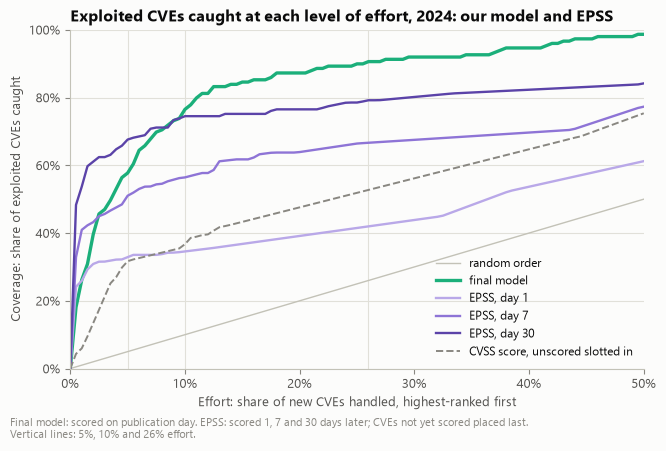

In [14]:
def coverage_curves(y, scores, styles, rules, title, name, note):
    "Coverage against effort (0-50%) for several rankings, with the Q1 rules as points."
    efforts = np.linspace(0, 0.5, 101)
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    ax.plot([0, 0.5], [0, 0.5], color=AXIS, linewidth=1, label="random order")
    for label, (color, width, dash) in styles.items():
        ax.plot(efforts, coverage(Ranking(scores[label]), y, efforts)[0], color=color, linewidth=width,
                linestyle=dash, label=label)
    beyond = [f"{r.replace('rule: ', '')} ({e:.0%} effort, {c:.0%} coverage)" for r, (e, c) in rules.items() if e > 0.5]
    for rule, (effort, cov) in ((r, ec) for r, ec in rules.items() if ec[0] <= 0.5):
        ax.plot(effort, cov, "o", color=INK, markersize=5, zorder=4)
        ax.annotate(rule.replace("rule: ", ""), (effort, cov), xytext=(6, -12), textcoords="offset points",
                    fontsize=8, color=INK_2)
    for e in EFFORTS:
        ax.axvline(e, color=GRID, linewidth=0.8, zorder=0)
    ax.set_xlim(0, 0.5)
    ax.set_ylim(0, 1.0)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y")
    ax.set_xlabel("Effort: share of new CVEs handled, highest-ranked first")
    ax.set_ylabel("Coverage: share of exploited CVEs caught")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8.5)
    save_figure(fig, name, note + (f"\nBeyond the right edge: rule {'; '.join(beyond)}." if beyond else ""))

STYLES = {MODEL: (SET_COLORS["structured + text"], 2.4, "-"),
          **{EPSS[h]: (EPSS_COLORS[h], 1.7, "-") for h in HORIZONS},
          CVSS: (BASELINE_GREY, 1.4, "--")}
coverage_curves(y, SCORES, STYLES, {}, "Exploited CVEs caught at each level of effort, 2024: our model and EPSS",
                "q4_coverage", "Final model: scored on publication day. EPSS: scored 1, 7 and 30 days later; CVEs not "
                "yet scored placed last.\nVertical lines: 5%, 10% and 26% effort.")

**Reading the chart:** the higher a curve, the more exploited CVEs caught for the same work. Compare
the aqua curve (our model, on publication day) with the violet ones (EPSS, later): a violet curve
above the aqua one means EPSS, a few days on, ranks better.

*In the run of 15 Nov 2026:* EPSS day 30 (dark violet) shoots up in the first 2–3% of effort, faster than any other ranking,
then flattens; our model overtakes it near 9% and stays above. EPSS day 1 (light violet) flattens at
about a third: beyond its few high scores, its tied floor value cannot rank anything.

---

## Stage D · Equal information

### Step 12 · When do exploited CVEs reach KEV?

**What we are doing:** for the 2024 CVEs exploited within a year, counting how many KEV had already
listed on or before the publication day, within 1, 7 and 30 days, and later.

**Why:** EPSS reads KEV. By the time of its day-30 score, every CVE listed in its first month is
already marked in EPSS's inputs, and a high EPSS score for it is partly a report of the answer, not a
prediction. For those CVEs a warning also comes too late to matter: KEV itself has already raised the
alarm.

                                  exploited CVEs share  listed by then (cumulative)
on or before the publication day              40 26.8%                           40
1 day after                                   13  8.7%                           53
2 to 7 days                                   25 16.8%                           78
8 to 30 days                                  17 11.4%                           95
31 to 365 days                                54 36.2%                          149

median: 7 days after publication; listed before the publication day: 7


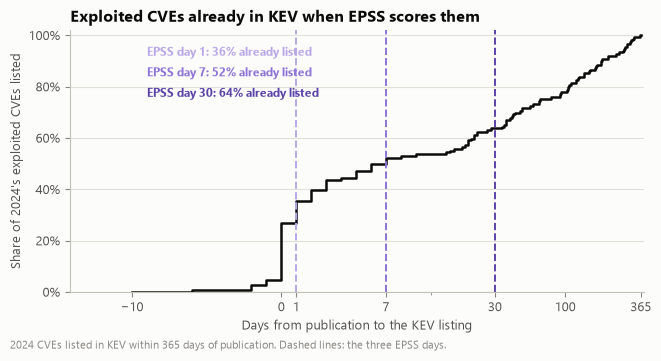

In [15]:
days = test.loc[y == 1, "days_to_kev"].astype(float)
bands = {"on or before the publication day": days <= 0, "1 day after": days == 1, "2 to 7 days": days.between(2, 7),
         "8 to 30 days": days.between(8, 30), "31 to 365 days": days > 30}
q4_timing = pd.DataFrame({"exploited CVEs": {k: int(v.sum()) for k, v in bands.items()}})
q4_timing["share"] = q4_timing["exploited CVEs"] / len(days)
q4_timing["listed by then (cumulative)"] = q4_timing["exploited CVEs"].cumsum()
print(q4_timing.to_string(formatters={"share": "{:.1%}".format}))
print(f"\nmedian: {days.median():.0f} days after publication; listed before the publication day: "
      f"{int(test.loc[y == 1, 'kev_before_publication'].sum())}")
save_table(q4_timing, "q4_listing_timing")

fig, ax = plt.subplots(figsize=(7.4, 3.4))
grid = np.arange(-10, 366)
ax.step(grid, [(days <= d).mean() for d in grid], where="post", color=INK, linewidth=1.8)
for h in HORIZONS:
    ax.axvline(h, color=EPSS_COLORS[h], linewidth=1.4, linestyle="--")
    ax.text(-9, 0.92 - 0.08 * HORIZONS.index(h), f"EPSS day {h}: {(days <= h).mean():.0%} already listed",
            fontsize=8.5, color=EPSS_COLORS[h], fontweight="bold")
ax.set_xscale("symlog", linthresh=10)
ax.set_xticks([-10, 0, 1, 7, 30, 100, 365], ["−10", "0", "1", "7", "30", "100", "365"])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.02)
ax.grid(axis="y")
ax.set_xlabel("Days from publication to the KEV listing")
ax.set_ylabel("Share of 2024's exploited CVEs listed")
ax.set_title("Exploited CVEs already in KEV when EPSS scores them")
save_figure(fig, "q4_listing_timing", "2024 CVEs listed in KEV within 365 days of publication. "
            "Dashed lines: the three EPSS days.")

**Reading the result:** the table counts exploited CVEs by how soon KEV listed them; the last column
adds them up. The chart shows the same thing as a curve: where it crosses each dashed line is the share
of exploited CVEs EPSS could already see listed on that day.

*In the run of 15 Nov 2026:* 40 of the 149 (26.8%) were listed on or before the publication day (7 of them before it), 53
within one day, 78 within a week and 95 within 30 days: the median is 7 days. So by its day-30 score,
EPSS could read the answer for 64% of the year's exploited CVEs.

### Step 13 · The comparison on equal information

**What we are doing:** for each EPSS day, leaving out the exploited CVEs that KEV had listed on or
before the day the EPSS score describes, and comparing the final model with that day's EPSS on the
CVEs that remain (every non-exploited CVE stays in). Each day gets its own paired bootstrap.

**Why:** these are the CVEs for which a ranking is still a *prediction* on that day, for both sides.
It is the fairest single comparison, and the one that matters to a team: they are the CVEs where an
early warning can still help. The same exclusion applies to both rankings, so neither is favoured.

In [16]:
def not_yet_listed(h):
    "False only for exploited CVEs that KEV had listed on or before the day EPSS's day-h score describes."
    listed = test["kev_date_added"].notna() & (test["kev_date_added"] <= pd.to_datetime(epss[f"day_{h}"]))
    return ~(listed.to_numpy() & (y == 1))

rows, KEEP = [], {}
for h in HORIZONS:
    keep = KEEP[h] = not_yet_listed(h)
    table_h, boot_h = evaluation_table(y[keep], {MODEL: SCORES[MODEL][keep], EPSS[h]: SCORES[EPSS[h]][keep]})
    for e in EFFORTS:
        change, low, high = difference(table_h, boot_h, EPSS[h], MODEL, e)
        rows.append({"epss_day": h, "exploited_kept": int(y[keep].sum()), "effort": e,
                     "final_model": table_h.loc[MODEL, f"coverage_{tag(e)}"],
                     "epss": table_h.loc[EPSS[h], f"coverage_{tag(e)}"], "change": change, "low": low, "high": high,
                     "ap_final_model": table_h.loc[MODEL, "average_precision"],
                     "ap_epss": table_h.loc[EPSS[h], "average_precision"]})
q4_fair = pd.DataFrame(rows)
q4_fair["clear"] = (q4_fair["low"] > 0) | (q4_fair["high"] < 0)
print(q4_fair.drop(columns=["ap_final_model", "ap_epss"]).to_string(
    index=False, formatters={**FMT, "final_model": "{:.1%}".format, "epss": "{:.1%}".format}))
save_table(q4_fair, "q4_equal_information", index=False)

print("\naverage precision, all CVEs -> equal information:")
for h in HORIZONS:
    r = q4_fair[q4_fair["epss_day"] == h].iloc[0]
    top = np.argsort(-SCORES[EPSS[h]], kind="stable")[:100]           # EPSS's 100 highest scores that day
    print(f"  day {h:>2}: final model {q4_all.loc[MODEL, 'average_precision']:.1%} -> {r['ap_final_model']:.1%}, "
          f"EPSS {q4_all.loc[EPSS[h], 'average_precision']:.1%} -> {r['ap_epss']:.1%} | EPSS's top 100: "
          f"{int(y[top].sum())} exploited, {int((~KEEP[h])[top].sum())} of them already in KEV")

failed = show_conditions({
    "no exploited CVE listed by the score day is left in": all(                 # written differently on purpose
        not (KEEP[h] & (y == 1) & ((pd.to_datetime(epss[f"day_{h}"]) - test["kev_date_added"]).dt.days >= 0)).any()
        for h in HORIZONS),
    "every non-exploited CVE is kept": all(KEEP[h][y == 0].all() for h in HORIZONS),
    "later EPSS days leave out at least as many exploited CVEs": all(
        int(y[KEEP[a]].sum()) >= int(y[KEEP[b]].sum()) for a, b in zip(HORIZONS, HORIZONS[1:])),
})
check("D1-equal-information", not failed, exploited_kept={h: int(y[KEEP[h]].sum()) for h in HORIZONS}, failed=failed)

 epss_day  exploited_kept effort final_model  epss change    low   high  clear
        1              96     5%       53.1% 13.5% +39.6% +28.4% +51.6%   True
        1              96    10%       74.0% 15.2% +58.8% +49.1% +68.7%   True
        1              96    26%       89.6% 24.5% +65.1% +55.3% +75.4%   True
        7              71     5%       49.3% 19.9% +29.4% +14.3% +44.4%   True
        7              71    10%       74.6% 26.8% +47.9% +34.7% +61.7%   True
        7              71    26%       90.1% 41.2% +49.0% +35.3% +63.1%   True
       30              54     5%       48.1% 35.5% +12.6%  -1.9% +28.5%  False
       30              54    10%       75.9% 46.3% +29.6% +15.7% +44.1%   True
       30              54    26%       88.9% 51.9% +37.0% +21.8% +52.3%   True

average precision, all CVEs -> equal information:
  day  1: final model 8.2% -> 3.8%, EPSS 17.0% -> 0.6% | EPSS's top 100: 36 exploited, 35 of them already in KEV
  day  7: final model 8.2% -> 2.4%, EPSS 26.2%

**Reading the result:** for each EPSS day and effort, how many exploited CVEs remain, the coverage of
each ranking on them, and the final model minus EPSS with its interval; then each ranking's average
precision before and after leaving out the already-listed CVEs, with what EPSS put in its 100 highest
places that day (exploited CVEs, and how many of them KEV had already listed); then three `ok` lines
and `PASS`.

*In the run of 15 Nov 2026:* with the already-listed CVEs left out, the gap widens. At 10% effort: 96 exploited CVEs remain
on day 1, of which the model catches 74.0% and EPSS 15.2% (+58.8 points, +49.1 to +68.7); on day 7,
74.6% against 26.8% (+47.9); on day 30, 75.9% against 46.3% (+29.6, +15.7 to +44.1). All clear, and
clear at every effort except 5% on day 30 (+12.6, −1.9 to +28.5). The model's coverage hardly moves
(74–76%), so it does not rely on CVEs that were already known. EPSS's does: its average precision on
day 1 falls from 17.0% to 0.6%, because 35 of the 36 exploited CVEs in its 100 highest places were
already in KEV. **EPSS's early strength at the top of the list is mostly a report of KEV listings,
not a prediction.** A positive `change` with `clear` means our publication-day model catches more of the CVEs
that were still unlisted than EPSS did with a head start of 1, 7 or 30 days.

### Step 14 · Sensitivity checks

**What we are doing:** coverage at 10% effort on all 2024 CVEs, then on three subsets:

1. **CVEs scored by EPSS on all three days:** so EPSS is not penalised for CVEs it had not scored yet.
2. **Without CVEs listed before publication:** their outcome was known before either ranking existed.
3. **Without the WordPress plug-in publishers:** many CVEs, almost none exploited, easy to rank last.

**Why:** a conclusion that changes on one of these subsets rests on that group of CVEs.

In [17]:
_sources = read_json(RAW / "nvd_sources.json") or []
PUBLISHER_NAMES = {identifier: s["name"].strip() for s in _sources if s.get("name")
                   for identifier in s.get("sourceIdentifiers", [])}

WORDPRESS = re.compile(r"wordfence|patchstack|wpscan", re.IGNORECASE)

def publisher_of(df):
    "The publisher's name where known, otherwise its identifier."
    return df["cna"].map(PUBLISHER_NAMES).fillna(df["cna"])

def is_wordpress(df):
    "True for CVEs issued by the WordPress plug-in publishers."
    return publisher_of(df).str.contains(WORDPRESS) | df["cna"].str.contains(WORDPRESS)

def coverage_row(y, score, mask=None):
    "Coverage at each effort for one ranking, optionally on a subset of CVEs."
    mask = np.ones(len(y), dtype=bool) if mask is None else mask
    return coverage(Ranking(score[mask]), y[mask], EFFORTS)[0]

SUBSETS = {"all 2024 CVEs": np.ones(len(test), dtype=bool),
           "scored by EPSS on all three days": epss[[f"epss_{h}" for h in HORIZONS]].notna().all(axis=1).to_numpy(),
           "without listed-before-publication": ~test["kev_before_publication"].to_numpy(bool),
           "without WordPress publishers": ~is_wordpress(test).to_numpy(bool)}
at_primary = EFFORTS.index(PRIMARY_EFFORT)
q4_sens = pd.DataFrame({subset: {name: coverage_row(y, s, mask)[at_primary] for name, s in SCORES.items()}
                        for subset, mask in SUBSETS.items()})
q4_sens.loc["exploited CVEs"] = [int(y[mask].sum()) for mask in SUBSETS.values()]
print(f"coverage at {PRIMARY_EFFORT:.0%} effort:\n")
print(q4_sens.to_string(float_format=lambda v: f"{v:.1%}" if v <= 1 else f"{v:.0f}"))
save_table(q4_sens, "q4_sensitivity")

coverage at 10% effort:

                                        all 2024 CVEs  scored by EPSS on all three days  without listed-before-publication  without WordPress publishers
final model                                     76.5%                             76.8%                              76.8%                         69.8%
EPSS, day 1                                     34.6%                             37.0%                              32.8%                         35.1%
EPSS, day 7                                     56.4%                             55.8%                              55.0%                         55.8%
EPSS, day 30                                    74.5%                             73.9%                              73.9%                         72.5%
CVSS score, unscored slotted in                 36.7%                             37.3%                              37.8%                         36.9%
Publisher's past rate                           64.5%    

WindowsPath('results/q4_sensitivity.csv')

**Reading the result:** one column per subset (the last row gives its number of exploited CVEs), one
row per ranking. If the order of the rankings holds across the columns, the conclusions do not depend
on these groups.

*In the run of 15 Nov 2026:* on CVEs scored on all three days, EPSS day 1 rises only to 37.0% (the model 76.8%): its gaps are
not why it trails. Without the pre-publication listings nothing changes. Without the WordPress
publishers the model falls to 69.8% and **EPSS day 30 (72.5%) is slightly ahead of it**, on all CVEs
(not equal information; this column has no interval). The model's lead over EPSS days 1 and 7 holds
everywhere.

---

## Stage E · Where the two disagree

### Step 15 · Each CVE's chance of being in the top 10%

**What we are doing:** a small tool that gives, for every CVE, its chance of being inside the top
share of a ranking, with ties split evenly, exactly as the coverage measure does: 1 above the cut, 0
below it, and the fraction taken for the tie group that holds the cut.

**Why:** to say which exploited CVEs each ranking catches, CVE by CVE. With EPSS's many ties, "is this
CVE in the top 10%?" has no yes-or-no answer for the CVEs in the tied group at the cut; the expected
share is the honest answer, and it adds up exactly to the coverage of Step 9. The self-test checks that.

In [18]:
def inclusion(score, effort):
    "Each CVE's chance of being in the top `effort` share, ties split evenly (the coverage rule, CVE by CVE)."
    ranking = Ranking(score)
    size = np.bincount(ranking.group, minlength=ranking.n_groups)
    before = np.cumsum(size) - size                                # CVEs in higher tie groups
    taken = np.clip((effort * ranking.n - before) / size, 0, 1)   # share of each tie group inside the cut
    chance = np.empty(ranking.n)
    chance[ranking.order] = taken[ranking.group]
    return chance

_tied = inclusion(np.array([9.8, 9.8, 7.5, 7.5, 7.5, 7.5, 5.0, 5.0, 3.1, 3.1]), 0.3)
failed = show_conditions({
    "a tie group straddling the cut: the two 9.8s fully in, the four 7.5s a quarter each":
        np.allclose(_tied, [1, 1, .25, .25, .25, .25, 0, 0, 0, 0]),
    "the chances add up to the number of CVEs handled, for every ranking":
        all(np.isclose(inclusion(s, PRIMARY_EFFORT).sum(), PRIMARY_EFFORT * len(s)) for s in SCORES.values()),
    "summed over exploited CVEs, they give the coverage of Step 9, for every ranking":
        all(np.isclose(inclusion(s, PRIMARY_EFFORT)[y == 1].sum() / y.sum(), q4_all.loc[n, "coverage_10"])
            for n, s in SCORES.items()),
})
check("E1-inclusion-selftest", not failed, tests=3, failed=failed)

  ok  a tie group straddling the cut: the two 9.8s fully in, the four 7.5s a quarter each
  ok  the chances add up to the number of CVEs handled, for every ranking
  ok  summed over exploited CVEs, they give the coverage of Step 9, for every ranking
PASS  E1-inclusion-selftest  |  {'tests': 3, 'failed': []}


**Reading the result:** three `ok` lines and `PASS`: the CVE-by-CVE chances agree with the coverage
measure.

### Step 16 · Caught by both, by one, or by neither

**What we are doing:** for the 2024 exploited CVEs, the expected number caught at 10% effort by both
our model and EPSS, by only one of them, and by neither, for each EPSS day; how much the two top-10%
lists overlap over all CVEs; and the rank correlation of the two scores.

**Why:** two rankings with similar coverage can catch the same CVEs or different ones. If they catch
different ones, they carry different information, and combining them could help (Step 18).

The expected count "caught by both" multiplies the two chances for each CVE (the tie-breaks of the two
rankings are independent). The **Spearman correlation** compares the two orders: 1 means the same
order, 0 no relation.

In [19]:
model_in = inclusion(SCORES[MODEL], PRIMARY_EFFORT)
rows = []
for h in HORIZONS:
    epss_in = inclusion(SCORES[EPSS[h]], PRIMARY_EFFORT)
    m, e = model_in[y == 1], epss_in[y == 1]
    rows.append({"epss_day": h, "both": (m * e).sum(), "final model only": (m * (1 - e)).sum(),
                 "EPSS only": ((1 - m) * e).sum(), "neither": ((1 - m) * (1 - e)).sum(),
                 "top-10% lists overlap (all CVEs)": (model_in * epss_in).sum() / (PRIMARY_EFFORT * len(y)),
                 "rank correlation (all CVEs)": spearmanr(SCORES[MODEL], SCORES[EPSS[h]]).statistic})
q4_overlap = pd.DataFrame(rows).set_index("epss_day")
print(f"{int(y.sum())} exploited CVEs, expected counts at {PRIMARY_EFFORT:.0%} effort:\n")
shown_as = {c: "{:.1f}".format for c in ("both", "final model only", "EPSS only", "neither")}
shown_as.update({"top-10% lists overlap (all CVEs)": "{:.1%}".format, "rank correlation (all CVEs)": "{:.2f}".format})
print(q4_overlap.to_string(formatters=shown_as))
save_table(q4_overlap, "q4_overlap")

149 exploited CVEs, expected counts at 10% effort:

         both final model only EPSS only neither top-10% lists overlap (all CVEs) rank correlation (all CVEs)
epss_day                                                                                                     
1        46.3             67.7       5.3    29.7                            19.9%                        0.00
7        66.0             48.0      18.1    16.9                            19.2%                       -0.00
30       87.0             27.0      24.0    11.0                            21.9%                       -0.00


WindowsPath('results/q4_overlap.csv')

**Reading the result:** one row per EPSS day. The first four columns add up to the number of exploited
CVEs; "final model only" and "EPSS only" are the disagreements. The overlap is the share of the
top-10% list the two have in common. Fractions appear because of EPSS's tied scores.

*In the run of 15 Nov 2026:* against EPSS day 1, about 46 exploited CVEs are caught by both, 68 by our model only, 5 by EPSS
only and 30 by neither; by day 30: 87, 27, 24 and 11. The two top-10% lists share only about a fifth of
their CVEs, and the rank correlation over all CVEs is about zero on every day: most CVEs sit on EPSS's
floor, and elsewhere its order has nothing to do with ours. The two rankings use different information.

**The picture:** the same four groups as bars, one per EPSS day.

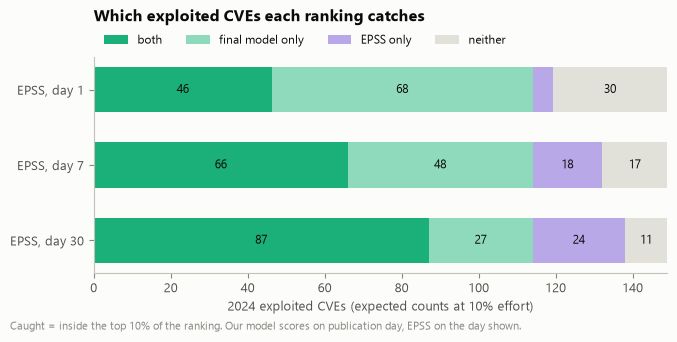

In [20]:
fig, ax = plt.subplots(figsize=(7.4, 2.8))
parts = [("both", SET_COLORS["structured + text"]), ("final model only", "#8fd9bd"), ("EPSS only", "#b9a8e8"),
         ("neither", "#e1e0d9")]
for i, h in enumerate(HORIZONS[::-1]):
    left = 0.0
    for name, color in parts:
        value = q4_overlap.loc[h, name]
        ax.barh(i, value, left=left, color=color, height=0.6, label=name if i == 0 else None)
        if value >= 6:
            ax.text(left + value / 2, i, f"{value:.0f}", ha="center", va="center", fontsize=8.5, color=INK)
        left += value
ax.set_yticks(range(len(HORIZONS)), [f"EPSS, day {h}" for h in HORIZONS[::-1]])
ax.set_xlim(0, y.sum())
ax.set_xlabel(f"2024 exploited CVEs (expected counts at {PRIMARY_EFFORT:.0%} effort)")
ax.set_title("Which exploited CVEs each ranking catches", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=8.5)
save_figure(fig, "q4_disagreement", "Caught = inside the top 10% of the ranking. Our model scores on publication day, "
            "EPSS on the day shown.")

**Reading the chart:** the longer the two light segments, the more the rankings disagree about which
exploited CVEs to put first.

### Step 17 · Who are the CVEs only one of them catches?

**What we are doing:** splitting the exploited CVEs that only one ranking catches (EPSS day 1) by
publisher, and listing the publishers with the most of them.

**Why:** this shows *what kind* of information each side has. Our model knows publishers' records and
the wording of descriptions; EPSS knows exploit code, chatter and lists such as KEV. The publishers on
each side are a concrete reading of that difference.

In [21]:
epss1_in = inclusion(SCORES[EPSS[1]], PRIMARY_EFFORT)
exploited = test.loc[y == 1, ["cve_id"]].assign(publisher=publisher_of(test.loc[y == 1]),
                                                 final_model_only=(model_in * (1 - epss1_in))[y == 1],
                                                 epss_day1_only=((1 - model_in) * epss1_in)[y == 1],
                                                 neither=((1 - model_in) * (1 - epss1_in))[y == 1])
by_publisher = (exploited.groupby("publisher")[["final_model_only", "epss_day1_only", "neither"]].sum()
                .assign(exploited=exploited.groupby("publisher").size()))
by_publisher = by_publisher[(by_publisher[["final_model_only", "epss_day1_only"]].sum(axis=1)) >= 0.5]
by_publisher = by_publisher.sort_values(["final_model_only", "epss_day1_only"], ascending=False)
print(by_publisher.round(1).head(15).to_string())
save_table(by_publisher, "q4_disagreement_publishers")

                               final_model_only  epss_day1_only  neither  exploited
publisher                                                                          
Microsoft Corporation                       7.0             2.0      0.0         31
MITRE                                       6.0             0.0      5.0         12
Apple Inc.                                  5.0             0.0      0.0          6
Chrome                                      5.0             0.0      0.0          7
HackerOne                                   4.0             0.0      1.0          6
Palo Alto Networks, Inc.                    4.0             0.0      0.0          7
VulnCheck                                   4.0             0.0      0.0          4
Progress Software Corporation               3.7             0.0      0.0          4
Apache Software Foundation                  3.0             0.0      2.0          5
Citrix Systems, Inc.                        3.0             0.0      1.0    

WindowsPath('results/q4_disagreement_publishers.csv')

**Reading the result:** one row per publisher with at least half an exploited CVE that only one
ranking catches (expected counts), the publisher's number of exploited CVEs in 2024, and how many
neither catches. Small numbers: read them as examples, not as rates.

*In the run of 15 Nov 2026:* our model's extra catches are spread over the vendors whose track record it learned (Microsoft 7,
Apple 5, Chrome 5, Palo Alto Networks 4, Progress 3.7, Citrix 3, VMware 3) and MITRE's CVEs (6), which
it ranks from the description. EPSS day 1's five extra catches are 2 from Microsoft and 1 each from
Cisco, Android and Google Devices.

### Step 18 · Does combining them help?

**What we are doing:** reading the last six rows of Step 10's differences: the average-rank
combination (fixed in Step 2) against our model alone and against EPSS day 1 alone.

**Why:** if the two rankings catch different CVEs (Step 16), a team that has both a day after
publication may do better with both. This is exploratory: the combination was fixed before any
result, but it is one simple rule, not a tuned model.

In [22]:
combined_rows = q4_diff[q4_diff["ranking"] == COMBINED]
print(combined_rows.to_string(index=False, formatters=FMT))
print(f"\ncoverage of the combination: " + ", ".join(f"{e:.0%} effort {q4_all.loc[COMBINED, f'coverage_{tag(e)}']:.1%}"
                                                     for e in EFFORTS))
floor = SCORES[EPSS[1]] <= q4_epss_shape.loc[EPSS[1], "most common value"]    # EPSS's most common score, or unscored
combined_in = inclusion(SCORES[COMBINED], PRIMARY_EFFORT)
print(f"EPSS day 1 at its most common score or unscored: {floor.mean():.1%} of CVEs")
print(f"the combination's top 10%: {combined_in[floor].sum() / combined_in.sum():.1%} from those CVEs, "
      f"{(combined_in * model_in).sum() / combined_in.sum():.1%} also in the final model's top 10%")

                               ranking       minus effort change    low   high  clear
average rank: final model + EPSS day 1 final model     5% -17.4% -26.8%  -7.1%   True
average rank: final model + EPSS day 1 final model    10% -30.9% -39.9% -22.0%   True
average rank: final model + EPSS day 1 final model    26% -12.1% -19.1%  -5.8%   True
average rank: final model + EPSS day 1 EPSS, day 1     5%  +7.4%  +3.1% +12.6%   True
average rank: final model + EPSS day 1 EPSS, day 1    10% +11.1%  +6.2% +16.1%   True
average rank: final model + EPSS day 1 EPSS, day 1    26% +36.6% +28.4% +44.3%   True

coverage of the combination: 5% effort 40.3%, 10% effort 45.6%, 26% effort 78.5%
EPSS day 1 at its most common score or unscored: 61.8% of CVEs
the combination's top 10%: 0.0% from those CVEs, 38.7% also in the final model's top 10%


**Reading the result:** the combination minus the final model, and minus EPSS day 1, at each effort,
with intervals, then the combination's coverage. A clear positive change against both would mean each
side adds something the other lacks. The last two lines show how the combination's top 10% is made
up: how many of its CVEs sit on EPSS's floor (its most common score, or not yet scored), and how many
the final model also puts in its top 10%.

*In the run of 15 Nov 2026:* the combination catches 40.3%, 45.6% and 78.5%: clearly **worse than our model alone** (−30.9
points at 10%, −39.9 to −22.0) though better than EPSS day 1 alone. The diagnostic lines say why: 61.8%
of CVEs sit on EPSS day 1's floor, and their average rank can never reach the top, so none of them is in
the combination's top 10%. But 61% of our model's own top 10%, and 52 of the 114 exploited CVEs it
catches there, sit on that floor. Averaging ranks with a score that is mostly ties throws that away. A
better combination would have to be designed and tuned on 2023, which needs EPSS scores for 2023 CVEs
(not collected): this is left as future work, and the equal-weight rule is reported as it was fixed.

---

## Stage F · Summary

### Step 19 · Key findings, and the scores for the demo

**What we are doing:** collecting the headline numbers in `results/q4_summary.json`, and saving every
ranking's 2024 scores in one file, `data/processed/q4_scores_test.parquet`, for the demo app.

**Why:** the report, the slides and the demo take their numbers from these files, never copied by hand.

In [23]:
def at(table_, name, effort):
    "Coverage of one ranking at one effort, with its interval, as text."
    est, low, high = (table_.loc[name, f"coverage_{tag(effort)}{s}"] for s in ("", "_low", "_high"))
    return f"{est:.1%} ({low:.1%}–{high:.1%})"

def change_text(row):
    return f"{row['change']:+.1%} ({row['low']:+.1%} to {row['high']:+.1%}){'' if row['clear'] else ', not clear'}"

d10 = q4_diff[np.isclose(q4_diff["effort"], PRIMARY_EFFORT)].set_index(["ranking", "minus"])
f10 = q4_fair[np.isclose(q4_fair["effort"], PRIMARY_EFFORT)].set_index("epss_day")
FINDINGS = {
    "final model": f"{FINAL} {SELECTION['candidates'][FINAL]['params']}, scored on publication day",
    "EPSS": f"model {', '.join(versions)}; scored on day 1/7/30: "
            + ", ".join(f"{epss[f'epss_{h}'].notna().mean():.1%}" for h in HORIZONS) + " of 2024 CVEs",
    "coverage at 10% effort, all 2024 CVEs": "; ".join(f"{n}: {at(q4_all, n, PRIMARY_EFFORT)}" for n in SCORES),
    "final model minus EPSS at 10%, all CVEs": "; ".join(f"day {h}: {change_text(d10.loc[(MODEL, EPSS[h])])}"
                                                         for h in HORIZONS),
    "exploited CVEs already in KEV on EPSS day 1/7/30": ", ".join(
        f"{int(y.sum()) - int(f10.loc[h, 'exploited_kept'])}" for h in HORIZONS) + f" of {int(y.sum())}",
    "final model minus EPSS at 10%, equal information": "; ".join(
        f"day {h} ({int(f10.loc[h, 'exploited_kept'])} exploited): {change_text(f10.loc[h])}" for h in HORIZONS),
    "caught at 10% (EPSS day 1): both / model only / EPSS only / neither": " / ".join(
        f"{q4_overlap.loc[1, c]:.1f}" for c in ("both", "final model only", "EPSS only", "neither")),
    "combination minus final model at 10%": change_text(d10.loc[(COMBINED, MODEL)]),
}
for topic, text in FINDINGS.items():
    print(f"- {topic}: {text}")
save_json(FINDINGS, RESULTS / "q4_summary.json")
pd.DataFrame({"cve_id": test["cve_id"], **SCORES}).to_parquet(PROCESSED / "q4_scores_test.parquet", index=False)
RUN["files"].append(str(PROCESSED / "q4_scores_test.parquet"))

- final model: LR · structured + text {'C': 0.1}, scored on publication day
- EPSS: model v2023.03.01; scored on day 1/7/30: 92.0%, 98.3%, 98.7% of 2024 CVEs
- coverage at 10% effort, all 2024 CVEs: final model: 76.5% (68.8%–83.5%); EPSS, day 1: 34.6% (27.5%–42.0%); EPSS, day 7: 56.4% (48.7%–63.7%); EPSS, day 30: 74.5% (67.6%–80.7%); CVSS score, unscored slotted in: 36.7% (28.9%–44.9%); Publisher's past rate: 64.5% (56.8%–71.9%); average rank: final model + EPSS day 1: 45.6% (37.5%–53.8%)
- final model minus EPSS at 10%, all CVEs: day 1: +41.9% (+32.3% to +51.3%); day 7: +20.1% (+9.1% to +30.6%); day 30: +2.0% (-7.7% to +11.2%), not clear
- exploited CVEs already in KEV on EPSS day 1/7/30: 53, 78, 95 of 149
- final model minus EPSS at 10%, equal information: day 1 (96 exploited): +58.8% (+49.1% to +68.7%); day 7 (71 exploited): +47.9% (+34.7% to +61.7%); day 30 (54 exploited): +29.6% (+15.7% to +44.1%)
- caught at 10% (EPSS day 1): both / model only / EPSS only / neither: 46.3 / 67.7 /

**Reading the result:** one line per headline finding, with 95% intervals in brackets ("not clear"
marks an interval that includes zero).

**The checks and files:** the last cell lists every check and every file this run wrote, and saves
the run log.

In [24]:
EXPECTED_CHECKS = ["A1-evaluation-selftest", "B1-inputs-from-03", "B2-epss-benchmark", "D1-equal-information",
                   "E1-inclusion-selftest"]
for name in EXPECTED_CHECKS:
    RUN["checks"].setdefault(name, {"verdict": "FAIL", "error": "check never ran"})
RUN["finished"] = now_iso()
LOG_FILE.write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")

verdicts = [c["verdict"] for c in RUN["checks"].values()]
print(f"{verdicts.count('PASS')}/{len(verdicts)} checks passed, {verdicts.count('WARN')} to review, "
      f"{verdicts.count('FAIL')} failed")
for name, c in RUN["checks"].items():
    print(f"  {c['verdict']:<5} {name}")
print(f"\n{len(RUN['files'])} files written:")
for path in RUN["files"]:
    print(f"  {path}")

5/5 checks passed, 0 to review, 0 failed
  PASS  A1-evaluation-selftest
  PASS  B1-inputs-from-03
  PASS  B2-epss-benchmark
  PASS  D1-equal-information
  PASS  E1-inclusion-selftest

13 files written:
  results\q4_epss_shape.csv
  results\q4_all_cves.csv
  results\q4_differences.csv
  figures\q4_coverage.png
  results\q4_listing_timing.csv
  figures\q4_listing_timing.png
  results\q4_equal_information.csv
  results\q4_sensitivity.csv
  results\q4_overlap.csv
  figures\q4_disagreement.png
  results\q4_disagreement_publishers.csv
  results\q4_summary.json
  data\processed\q4_scores_test.parquet


**Reading the result:** the target is 5 of 5 checks passed. `B1` may be `WARN` if the test year was
opened more than once (see Step 5).

## What comes next

1. **The demo app** reads `data/processed/q4_scores_test.parquet` (every ranking's 2024 scores) and the
   result tables of 03 and 04.
2. **`05_pytorch_extension.ipynb`** adds its 2024 scores to this comparison with the same tools.
3. **The report** takes Q4's numbers from `results/q4_summary.json` and the `q4_*.csv` tables.